<a href="https://colab.research.google.com/github/akashkumarcs24-cloud/BIS_LAB/blob/main/AntColonyOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running Improved Ant Colony Optimization...
-------------------------------------------------------
Iteration   1 | Current iteration best: 31.59 | Overall best: 31.59
Iteration  20 | Current iteration best: 29.46 | Overall best: 29.46
Iteration  40 | Current iteration best: 29.46 | Overall best: 29.46
Iteration  60 | Current iteration best: 29.46 | Overall best: 29.46
Iteration  80 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 100 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 120 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 140 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 160 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 180 | Current iteration best: 29.46 | Overall best: 29.46
Iteration 200 | Current iteration best: 29.46 | Overall best: 29.46

OPTIMIZED LOGISTICS ROUTE RESULTS
Best route: 0 -> 1 -> 5 -> 6 -> 3 -> 7 -> 4 -> 2 -> 0
Total distance: 29.46 units

Individual route segments:
0 -> 1:

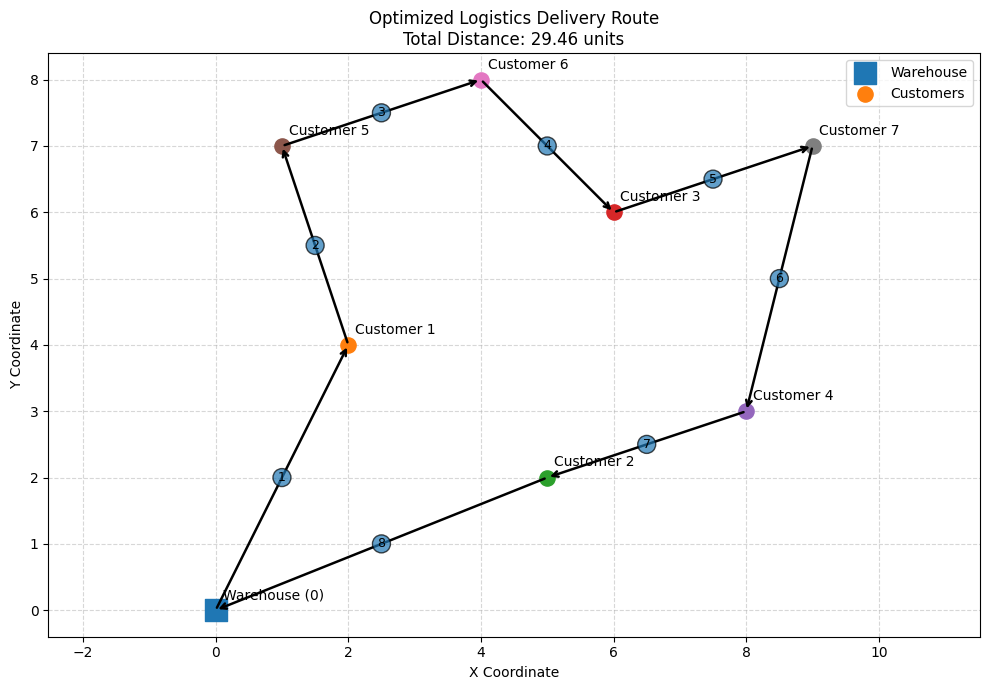

Graph 2: Convergence of Best Route Distance


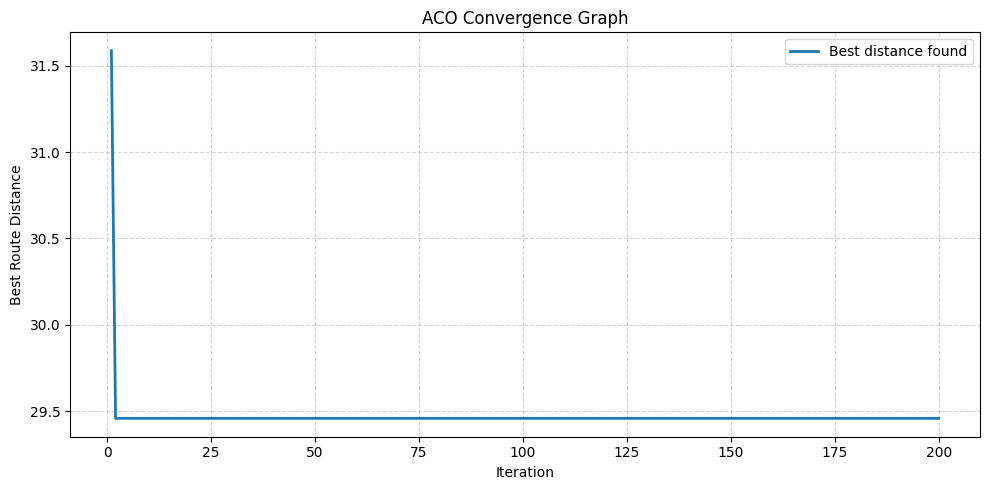

In [ ]:

import math
import random
import matplotlib.pyplot as plt
from IPython.display import display

# =====================================================
# IMPROVED ANT COLONY OPTIMIZATION (MMAS)
# Logistics and Distribution Route Optimization
# Google Colab Version
# =====================================================

# 0 = warehouse, remaining points = customers
locations = {
    0: (0, 0),
    1: (2, 4),
    2: (5, 2),
    3: (6, 6),
    4: (8, 3),
    5: (1, 7),
    6: (4, 8),
    7: (9, 7)
}

# Algorithm parameters
NUM_ANTS = 20
ITERATIONS = 200
ALPHA = 1.0
BETA = 3.0
EVAPORATION = 0.5
PHEROMONE_MIN_FACTOR = 0.05

random.seed(42)

nodes = list(locations.keys())
n = len(nodes)


# 1. Calculate distances between locations
distance = [[0.0] * n for _ in range(n)]

for i in nodes:
    for j in nodes:
        x1, y1 = locations[i]
        x2, y2 = locations[j]
        distance[i][j] = math.hypot(x1 - x2, y1 - y2)


# 2. Initialize pheromone trails
pheromone = [[1.0] * n for _ in range(n)]

for i in nodes:
    pheromone[i][i] = 0.0


# 3. Calculate total distance of a route
def calculate_route_distance(route):
    return sum(
        distance[route[i]][route[i + 1]]
        for i in range(len(route) - 1)
    )


# 4. Select the next customer using ACO probabilities
def select_next_city(current_city, unvisited):
    weights = []

    for city in unvisited:
        tau = pheromone[current_city][city] ** ALPHA
        eta = (1.0 / distance[current_city][city]) ** BETA
        weights.append(tau * eta)

    return random.choices(
        unvisited, weights=weights, k=1
    )[0]


# 5. Construct a route
def construct_route():
    route = [0]
    unvisited = set(nodes)
    unvisited.remove(0)

    while unvisited:
        current_city = route[-1]
        next_city = select_next_city(
            current_city, list(unvisited)
        )
        route.append(next_city)
        unvisited.remove(next_city)

    route.append(0)
    return route


# 6. Improved Ant Colony Optimization (MMAS)
def ant_colony_optimization():
    global pheromone

    best_route = None
    best_distance = float("inf")
    history = []

    print("Running Improved Ant Colony Optimization...")
    print("-" * 55)

    for iteration in range(1, ITERATIONS + 1):
        iteration_best_distance = float("inf")

        # Each ant constructs a possible route
        for _ in range(NUM_ANTS):
            route = construct_route()
            length = calculate_route_distance(route)

            iteration_best_distance = min(
                iteration_best_distance, length
            )

            if length < best_distance:
                best_distance = length
                best_route = route[:]

        # Pheromone evaporation
        for i in nodes:
            for j in nodes:
                if i != j:
                    pheromone[i][j] *= (1 - EVAPORATION)

        # Reinforce the best-so-far route
        deposit = 1.0 / best_distance

        for k in range(len(best_route) - 1):
            a = best_route[k]
            b = best_route[k + 1]

            pheromone[a][b] += EVAPORATION * deposit
            pheromone[b][a] += EVAPORATION * deposit

        # MMAS pheromone bounds
        tau_max = 1.0 / (EVAPORATION * best_distance)
        tau_min = PHEROMONE_MIN_FACTOR * tau_max

        for i in nodes:
            for j in nodes:
                if i != j:
                    pheromone[i][j] = max(
                        tau_min,
                        min(tau_max, pheromone[i][j])
                    )

        history.append(best_distance)

        if iteration % 20 == 0 or iteration == 1:
            print(
                f"Iteration {iteration:3d} | "
                f"Current iteration best: "
                f"{iteration_best_distance:.2f} | "
                f"Overall best: {best_distance:.2f}"
            )

    return best_route, best_distance, history


# 7. Plot the optimized delivery route
def plot_route(route, total_distance):
    plt.figure(figsize=(10, 7))

    # Plot warehouse and customer locations
    for city, (x, y) in locations.items():
        if city == 0:
            plt.scatter(
                x, y, s=250, marker="s",
                label="Warehouse", zorder=3
            )
            label = "Warehouse (0)"
        else:
            plt.scatter(
                x, y, s=120, marker="o",
                label="Customers" if city == 1 else None,
                zorder=3
            )
            label = f"Customer {city}"

        plt.annotate(
            label, (x, y),
            xytext=(5, 8),
            textcoords="offset points"
        )

    # Draw route with arrows
    for k in range(len(route) - 1):
        a = route[k]
        b = route[k + 1]

        x1, y1 = locations[a]
        x2, y2 = locations[b]

        plt.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops={"arrowstyle": "->", "linewidth": 1.8}
        )

        # Mark visiting order
        plt.text(
            (x1 + x2) / 2,
            (y1 + y2) / 2,
            str(k + 1),
            fontsize=9,
            ha="center",
            va="center",
            bbox={"boxstyle": "circle,pad=0.2", "alpha": 0.7}
        )

    plt.title(
        "Optimized Logistics Delivery Route\n"
        f"Total Distance: {total_distance:.2f} units"
    )
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


# 8. Plot the convergence graph
def plot_convergence(history):
    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(history) + 1),
        history,
        linewidth=2,
        label="Best distance found"
    )

    plt.title("ACO Convergence Graph")
    plt.xlabel("Iteration")
    plt.ylabel("Best Route Distance")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


# 9. Display final results
def display_results(route, total_distance):
    print("\n" + "=" * 55)
    print("OPTIMIZED LOGISTICS ROUTE RESULTS")
    print("=" * 55)

    print("Best route:", " -> ".join(map(str, route)))
    print(f"Total distance: {total_distance:.2f} units")

    print("\nIndividual route segments:")

    for k in range(len(route) - 1):
        a = route[k]
        b = route[k + 1]

        print(
            f"{a} -> {b}: "
            f"{distance[a][b]:.2f} units"
        )

    print("\nNumber of customers:", len(locations) - 1)
    print("Number of ants:", NUM_ANTS)
    print("Number of iterations:", ITERATIONS)
    print("Algorithm: Improved ACO (MMAS)")


# 10. Execute the program
best_route, best_distance, history = (
    ant_colony_optimization()
)

display_results(best_route, best_distance)

print("\nGraph 1: Optimized Delivery Route")
plot_route(best_route, best_distance)

print("Graph 2: Convergence of Best Route Distance")
plot_convergence(history)
